# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [17]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0


In [18]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [19]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [20]:
# Desarrollo

# Nombrando las columnas
COL_FECHA = "Fecha de Análisis"
COL_PH = "pH agua:suelo"
COL_DPTO_S = "Departamento"
COL_MPIO_S = "Municipio"
COL_COD_DPTO = "Código Departamento"
COL_NOM_DPTO = "Nombre Departamento"
COL_COD_MPIO = "Código Municipio"
COL_NOM_MPIO = "Nombre Municipio"
COL_LON = "longitud"
COL_LAT = "Latitud"

faltan_suelo = [c for c in [COL_FECHA, COL_PH, COL_DPTO_S, COL_MPIO_S] if c not in suelo.columns]
faltan_terr = [c for c in [COL_COD_DPTO, COL_NOM_DPTO, COL_COD_MPIO, COL_NOM_MPIO, COL_LON, COL_LAT] if c not in territorio.columns]
assert not faltan_suelo, f"Columnas ausentes en AGROSAVIA: {faltan_suelo}. Disponibles: {suelo.columns.tolist()}"
assert not faltan_terr, f"Columnas ausentes en DIVIPOLA: {faltan_terr}. Disponibles: {territorio.columns.tolist()}"

# Copias antes de transformar
suelo_original = suelo.copy()
territorio_original = territorio.copy()
conteos_entrada = pd.DataFrame({
    "tabla": ["agrosavia.csv", "divipola.csv"],
    "filas": [len(suelo_original), len(territorio_original)],
    "columnas": [suelo_original.shape[1], territorio_original.shape[1]],
})
display(conteos_entrada)

# Nulos, vacíos tras strip y marcador ND
perfil = []
for nombre_tabla, tabla in [("agrosavia", suelo_original), ("divipola", territorio_original)]:
    for col in tabla.columns:
        texto = tabla[col]
        recortado = texto.str.strip()
        perfil.append({
            "tabla": nombre_tabla,
            "columna": col,
            "dtype": str(texto.dtype),
            "nulos": int(texto.isna().sum()),
            "vacios_tras_strip": int(recortado.eq("").sum()),
            "marcador_ND": int(recortado.str.upper().eq("ND").sum()),
            "distintos": int(texto.nunique()),
        })
perfil = pd.DataFrame(perfil)
display(perfil)

# Secuencial
if "Secuencial" in suelo_original.columns:
    dup_sec = suelo_original["Secuencial"].duplicated(keep=False)
    print("Filas con Secuencial repetido:", int(dup_sec.sum()), "de", len(suelo_original))

# Examinando campos
print("\nFecha de análisis – valores más frecuentes:")
display(suelo_original[COL_FECHA].value_counts(dropna=False).head(10))
print("Longitudes de texto de fecha:")
display(suelo_original[COL_FECHA].str.strip().str.len().value_counts(dropna=False).sort_index())
print("\npH – muestra de valores distintos:")
display(suelo_original[COL_PH].drop_duplicates().head(15).tolist())
print("\nNombres territoriales en AGROSAVIA (pares más frecuentes):")
display(suelo_original[[COL_DPTO_S, COL_MPIO_S]].value_counts().head(15))
print("\nCoordenadas DIVIPOLA – ejemplos:")
display(territorio_original[[COL_NOM_MPIO, COL_LON, COL_LAT]].head(8))

,tabla,filas,columnas
0,agrosavia.csv,92738,32
1,divipola.csv,1122,7


,tabla,columna,dtype,nulos,vacios_tras_strip,marcador_ND,distintos
0,agrosavia,Secuencial,object,0,0,0,92738
1,agrosavia,Fecha de Análisis,object,0,0,0,2388
2,agrosavia,Departamento,object,0,0,0,33
3,agrosavia,Municipio,object,0,2,0,991
4,agrosavia,Cultivo,object,0,0,0,282
5,agrosavia,Estado,object,0,0,0,4
6,agrosavia,Tiempo de establecimiento,object,0,0,0,9
7,agrosavia,Topografia,object,0,0,0,13
8,agrosavia,Drenaje,object,0,0,0,6
9,agrosavia,Riego,object,0,0,0,17


Filas con Secuencial repetido: 0 de 92738

Fecha de análisis – valores más frecuentes:


Fecha de Análisis
5/08/2016     685
13/01/2016    511
21/01/2016    498
12/05/2014    495
5/05/2014     480
25/09/2015    468
1/12/2017     445
12/11/2014    426
26/06/2020    391
20/11/2014    374
Name: count, dtype: int64

Longitudes de texto de fecha:


...

['5.64',
 '4.24',
 '5.22',
 '5.45',
 '5.43',
 '6.92',
 '4.59',
 '4.849',
 '5.87',
 '5.24',
 '6.03',
 '5.46',
 '5.61',
 '5.89',
 '5.09']


Nombres territoriales en AGROSAVIA (pares más frecuentes):


Departamento        Municipio           
META                VILLAVICENCIO           2165
LA GUAJIRA          ALBANIA                 1645
VALLE DEL CAUCA     PALMIRA                 1353
META                PUERTO LÓPEZ            1339
NORTE DE SANTANDER  CÚCUTA                  1095
NARIÑO              SAN ANDRÉS DE TUMACO    1050
TOLIMA              ESPINAL                 1050
META                PUERTO GAITÁN           1017
CÓRDOBA             CERETÉ                   979
NARIÑO              POLICARPA                818
SANTANDER           EL CARMEN DE CHUCURÍ     813
CUNDINAMARCA        MOSQUERA                 779
BOLÍVAR             SAN PABLO                698
NARIÑO              PASTO                    658
VALLE DEL CAUCA     TULUÁ                    599
Name: count, dtype: int64


Coordenadas DIVIPOLA – ejemplos:


,Nombre Municipio,longitud,Latitud
0,MEDELLÍN,"-75,581775","6,246631"
1,ABEJORRAL,"-75,428739","5,789315"
2,ABRIAQUÍ,"-76,064304","6,632282"
3,ALEJANDRÍA,"-75,141346","6,376061"
4,AMAGÁ,"-75,702188","6,038708"
5,AMALFI,"-75,077501","6,909655"
6,ANDES,"-75,878828","5,657194"
7,ANGELÓPOLIS,"-75,711389","6,109719"


**Interpretación:**

AGROSAVIA tiene **92.738 filas y 32 columnas**; DIVIPOLA, **1.122 filas y 7 columnas**. Ambas tablas se leyeron como texto (`dtype=str`, `keep_default_na=False`), por eso no hay nulos: la ausencia aparece como texto vacío o como el marcador `ND`, y por esa razón se cuentan por separado. Las fechas, el pH y los nombres de departamento no tienen vacíos ni `ND`; `Municipio` tiene 2 vacíos. El `ND` se concentra en variables de laboratorio: 45.130 filas en acidez y aluminio intercambiable, y alrededor de 1.500 en fósforo y azufre. Un vacío (no registrado) y un `ND` (no determinado) no significan lo mismo, aunque ambos se tratarán como ausencia en las columnas tipadas sin alterar el texto original.

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [21]:
# Desarrollo

import numpy as np

MARCADORES_AUSENCIA = ["", "ND"]

suelo = suelo_original.copy()
suelo.insert(0, "id_fila", pd.array(np.arange(len(suelo)), dtype="Int64"))

# Fecha de análisis
fecha_txt = suelo[COL_FECHA].str.strip()
fecha_ausente = fecha_txt.isna() | fecha_txt.str.upper().isin(MARCADORES_AUSENCIA)
suelo["fecha_dt"] = pd.to_datetime(fecha_txt.mask(fecha_ausente), format="%d/%m/%Y", errors="coerce")
fecha_fallo = ~fecha_ausente & suelo["fecha_dt"].isna()
suelo["fecha_estado"] = np.select([fecha_ausente, fecha_fallo], ["ausente", "fallo_conversion"], default="valida")
suelo["anio"] = suelo["fecha_dt"].dt.year.astype("Int64")

# pH
ph_txt = suelo[COL_PH].str.strip()
ph_ausente = ph_txt.isna() | ph_txt.str.upper().isin(MARCADORES_AUSENCIA)
suelo["ph"] = pd.to_numeric(ph_txt.mask(ph_ausente), errors="coerce").astype("float64")
ph_fallo = ~ph_ausente & suelo["ph"].isna()
ph_fuera = suelo["ph"].notna() & ~suelo["ph"].between(0, 14)
suelo["ph_valido"] = suelo["ph"].notna() & suelo["ph"].between(0, 14)
suelo["ph_estado"] = np.select([ph_ausente, ph_fallo, ph_fuera], ["ausente", "fallo_conversion", "fuera_rango"], default="valido")

print("Estados de fecha:"); display(suelo["fecha_estado"].value_counts())
print("Ejemplos de fecha no convertible (máx. 5):")
display(suelo.loc[fecha_fallo, COL_FECHA].value_counts().head(5))
print("Distribución de años:"); display(suelo["anio"].value_counts(dropna=False).sort_index())

print("\nEstados de pH:"); display(suelo["ph_estado"].value_counts())
print("Ejemplos de pH no convertible (máx. 5):")
display(suelo.loc[ph_fallo, COL_PH].value_counts().head(5))
print("Ejemplos de pH fuera de [0, 14] (máx. 5):")
display(suelo.loc[ph_fuera, [COL_PH, "ph"]].drop_duplicates().head(5))
print("Descripción de pH válido:")
display(suelo.loc[suelo["ph_valido"], "ph"].describe())

# Coordenadas DIVIPOLA
territorio = territorio_original.copy()
print("\nRevisión previa de coordenadas (separadores presentes):")
for col in [COL_LON, COL_LAT]:
    t = territorio[col].str.strip()
    print(f"  {col}: con coma={int(t.str.contains(',', regex=False).sum())}, "
          f"con punto={int(t.str.contains('.', regex=False).sum())}, "
          f"con más de una coma={int(t.str.count(',').gt(1).sum())}, vacíos={int(t.eq('').sum())}")

lon_txt = territorio[COL_LON].str.strip()
lat_txt = territorio[COL_LAT].str.strip()
lon_ausente = lon_txt.isna() | lon_txt.str.upper().isin(MARCADORES_AUSENCIA)
lat_ausente = lat_txt.isna() | lat_txt.str.upper().isin(MARCADORES_AUSENCIA)

# Reemplazando la coma por punto
territorio["longitud_num"] = pd.to_numeric(lon_txt.mask(lon_ausente).str.replace(",", ".", regex=False), errors="coerce").astype("float64")
territorio["latitud_num"] = pd.to_numeric(lat_txt.mask(lat_ausente).str.replace(",", ".", regex=False), errors="coerce").astype("float64")
lon_fallo = ~lon_ausente & territorio["longitud_num"].isna()
lat_fallo = ~lat_ausente & territorio["latitud_num"].isna()
lon_fuera = territorio["longitud_num"].notna() & ~territorio["longitud_num"].between(-180, 180)
lat_fuera = territorio["latitud_num"].notna() & ~territorio["latitud_num"].between(-90, 90)

# Valores fuera de rango no se usan como coordenada, pero el registro se conserva
territorio.loc[lon_fuera, "longitud_num"] = np.nan
territorio.loc[lat_fuera, "latitud_num"] = np.nan

control_coordenadas = pd.DataFrame({
    "campo": [COL_LON, COL_LAT],
    "ausentes": [int(lon_ausente.sum()), int(lat_ausente.sum())],
    "fallo_conversion": [int(lon_fallo.sum()), int(lat_fallo.sum())],
    "fuera_rango": [int(lon_fuera.sum()), int(lat_fuera.sum())],
    "convertidas_validas": [int(territorio["longitud_num"].notna().sum()), int(territorio["latitud_num"].notna().sum())],
})
display(control_coordenadas)

print("Ejemplos de fallo en longitud:", territorio.loc[lon_fallo, COL_LON].head(5).tolist())
print("Ejemplos de fallo en latitud:", territorio.loc[lat_fallo, COL_LAT].head(5).tolist())

# Ejemplos
fuera_col = territorio["longitud_num"].notna() & territorio["latitud_num"].notna() & ~(
    territorio["longitud_num"].between(-82, -66) & territorio["latitud_num"].between(-5, 14))
print("Coordenadas válidas pero fuera de la caja aproximada de Colombia:", int(fuera_col.sum()))

control_conversion = pd.DataFrame({
    "control": ["fecha_ausente", "fecha_fallo", "ph_ausente", "ph_fallo", "ph_fuera_rango", "ph_valido",
                "lon_ausente", "lon_fallo", "lat_ausente", "lat_fallo"],
    "conteo": [int(fecha_ausente.sum()), int(fecha_fallo.sum()), int(ph_ausente.sum()), int(ph_fallo.sum()),
               int(ph_fuera.sum()), int(suelo["ph_valido"].sum()), int(lon_ausente.sum()), int(lon_fallo.sum()),
               int(lat_ausente.sum()), int(lat_fallo.sum())],
})
assert len(suelo) == len(suelo_original) and len(territorio) == len(territorio_original)


Estados de fecha:


fecha_estado
valida    92738
Name: count, dtype: int64

Ejemplos de fecha no convertible (máx. 5):


Series([], Name: count, dtype: int64)

Distribución de años:


...

Descripción de pH válido:


count    92727.000000
mean         5.708232
std          1.019957
min          3.190000
25%          4.960000
50%          5.470000
75%          6.260000
max         10.570000
Name: ph, dtype: float64


Revisión previa de coordenadas (separadores presentes):
  longitud: con coma=1122, con punto=0, con más de una coma=0, vacíos=0
  Latitud: con coma=1122, con punto=0, con más de una coma=0, vacíos=0


,campo,ausentes,fallo_conversion,fuera_rango,convertidas_validas
0,longitud,0,0,0,1122
1,Latitud,0,0,0,1122


Ejemplos de fallo en longitud: []
Ejemplos de fallo en latitud: []
Coordenadas válidas pero fuera de la caja aproximada de Colombia: 0


**Interpretación:**

Las 92.738 fechas se convirtieron con `%d/%m/%Y`, sin ausencias ni fallos. Cubren de 2014 a 2025, con el máximo en 2016 (14.539 análisis) y años recientes con menos registros (2.685 en 2025). En pH hay 92.727 valores válidos y 11 fallos de conversión: 6 censurados por debajo del límite de detección (`<3.80`), 4 por encima (`>10.00`) y 1 error de digitación (`4..01`). No hay valores fuera de [0, 14]. Los censurados no se reemplazaron por 3,8 ni por 10: hacerlo sesgaría la media. Quedan con `ph_valido = False` y su texto original. El pH válido va de 3,19 a 10,57, con una mediana de 5,47 (suelos mayoritariamente ácidos).

En DIVIPOLA, las 1.122 longitudes y latitudes usan coma decimal y ninguna tiene más de una coma. La sustitución coma→punto se aplicó solo a esas dos columnas: todas convirtieron, están dentro de [−180, 180] y [−90, 90] y caen en la caja aproximada de Colombia.

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [22]:
# Desarrollo

# Operaciones
for tabla, col_origen, col_clave in [
    (suelo, COL_DPTO_S, "clave_dpto"),
    (suelo, COL_MPIO_S, "clave_mpio"),
    (territorio, COL_NOM_DPTO, "clave_dpto"),
    (territorio, COL_NOM_MPIO, "clave_mpio"),
]:
    clave = (
        tabla[col_origen]
        .str.normalize("NFKD")
        .str.upper()
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )
    tabla[col_clave] = clave.mask(clave.isna() | clave.isin(MARCADORES_AUSENCIA))

print("Ejemplos de normalización (AGROSAVIA):")
display(suelo[[COL_DPTO_S, "clave_dpto", COL_MPIO_S, "clave_mpio"]].drop_duplicates().head(10))
print("Pérdida de distinción: textos originales distintos que comparten clave normalizada")
display(suelo.groupby(["clave_dpto", "clave_mpio"], dropna=False)[COL_MPIO_S].nunique()
        .loc[lambda s: s.gt(1)].head(10))

# Códigos DIVIPOLA como texto
cod_mpio_txt = territorio[COL_COD_MPIO].str.strip()
cod_dpto_txt = territorio[COL_COD_DPTO].str.strip()
print("Longitudes de Código Municipio:", cod_mpio_txt.str.len().value_counts().to_dict())
print("Longitudes de Código Departamento:", cod_dpto_txt.str.len().value_counts().to_dict())
mpio_ok = cod_mpio_txt.str.fullmatch(r"\d{4,5}").fillna(False).astype(bool)
dpto_ok = cod_dpto_txt.str.fullmatch(r"\d{1,2}").fillna(False).astype(bool)

# Relleno con ceros a la izquierda solo cuando el texto es numérico
territorio["codigo_municipio"] = cod_mpio_txt.where(mpio_ok).str.zfill(5)
territorio["codigo_departamento"] = cod_dpto_txt.where(dpto_ok).str.zfill(2)
print("Códigos municipales rellenados con cero:", int((mpio_ok & cod_mpio_txt.str.len().eq(4)).sum()))
print("Códigos municipales no válidos:", int((~mpio_ok).sum()), "| departamentales no válidos:", int((~dpto_ok).sum()))
incoherente = territorio["codigo_municipio"].notna() & territorio["codigo_departamento"].notna() & \
    territorio["codigo_municipio"].str[:2].ne(territorio["codigo_departamento"])
print("Códigos municipales cuyo prefijo no coincide con el departamento:", int(incoherente.sum()))

# Unicidad y colisiones
codigo_dup = territorio["codigo_municipio"].notna() & territorio["codigo_municipio"].duplicated(keep=False)
clave_incompleta_t = territorio["clave_dpto"].isna() | territorio["clave_mpio"].isna()
n_por_clave = territorio.groupby(["clave_dpto", "clave_mpio"])["clave_mpio"].transform("size")
clave_ambigua_t = ~clave_incompleta_t & n_por_clave.gt(1)
print("Códigos municipales duplicados:", int(codigo_dup.sum()))
print("Claves de nombre vacías en DIVIPOLA:", int(clave_incompleta_t.sum()))
print("Filas DIVIPOLA en claves compuestas ambiguas:", int(clave_ambigua_t.sum()))

# Verificación
homonimos = territorio.groupby("clave_mpio")["clave_dpto"].nunique().loc[lambda s: s.gt(1)]
print("Nombres municipales presentes en más de un departamento (no ambiguos con clave compuesta):", len(homonimos))

claves_ambiguas = territorio.loc[clave_ambigua_t | codigo_dup | clave_incompleta_t |
                                 territorio["codigo_municipio"].isna() | incoherente,
    [COL_COD_DPTO, COL_NOM_DPTO, COL_COD_MPIO, COL_NOM_MPIO, "clave_dpto", "clave_mpio", "codigo_municipio"]].copy()
claves_ambiguas["motivo"] = np.select(
    [clave_ambigua_t[claves_ambiguas.index], codigo_dup[claves_ambiguas.index],
     clave_incompleta_t[claves_ambiguas.index], territorio.loc[claves_ambiguas.index, "codigo_municipio"].isna()],
    ["clave_nombre_ambigua", "codigo_duplicado", "clave_nombre_incompleta", "codigo_invalido"],
    default="prefijo_incoherente")
claves_ambiguas.to_csv(OUT + "/claves_ambiguas.csv", index=False, encoding="utf-8-sig")
display(claves_ambiguas)

# Claves completas, no ambiguas y código válido
apta_dim = ~(clave_ambigua_t | codigo_dup | clave_incompleta_t | incoherente) & territorio["codigo_municipio"].notna()
dimension = territorio.loc[apta_dim, ["clave_dpto", "clave_mpio", "codigo_departamento", "codigo_municipio",
                                      COL_NOM_DPTO, COL_NOM_MPIO, "longitud_num", "latitud_num"]].rename(columns={
    COL_NOM_DPTO: "nombre_departamento_divipola",
    COL_NOM_MPIO: "nombre_municipio_divipola",
    "longitud_num": "longitud_territorial",
    "latitud_num": "latitud_territorial",
})
assert not dimension.duplicated(["clave_dpto", "clave_mpio"]).any()
assert dimension["codigo_municipio"].is_unique

# Atributos territoriales por código
territorio_por_codigo = territorio.loc[territorio["codigo_municipio"].notna() & ~codigo_dup & ~incoherente,
    ["codigo_municipio", "codigo_departamento", COL_NOM_DPTO, COL_NOM_MPIO, "clave_mpio", "longitud_num", "latitud_num"]
].rename(columns={COL_NOM_DPTO: "nombre_departamento_divipola", COL_NOM_MPIO: "nombre_municipio_divipola",
                  "clave_mpio": "clave_mpio_oficial",
                  "longitud_num": "longitud_territorial", "latitud_num": "latitud_territorial"})
print("Filas DIVIPOLA:", len(territorio), "| dimensión apta:", len(dimension), "| apartadas:", len(territorio) - len(dimension))

Ejemplos de normalización (AGROSAVIA):


,Departamento,clave_dpto,Municipio,clave_mpio
0,NARIÑO,NARIÑO,SAN ANDRÉS DE TUMACO,SAN ANDRÉS DE TUMACO
1,HUILA,HUILA,SANTA MARÍA,SANTA MARÍA
2,ANTIOQUIA,ANTIOQUIA,LIBORINA,LIBORINA
7,CUNDINAMARCA,CUNDINAMARCA,SILVANIA,SILVANIA
9,CUNDINAMARCA,CUNDINAMARCA,PASCA,PASCA
22,CUNDINAMARCA,CUNDINAMARCA,VILLETA,VILLETA
44,CESAR,CESAR,AGUSTÍN CODAZZI,AGUSTÍN CODAZZI
45,CUNDINAMARCA,CUNDINAMARCA,SAN BERNARDO,SAN BERNARDO
47,ANTIOQUIA,ANTIOQUIA,CARACOLÍ,CARACOLÍ
49,CUNDINAMARCA,CUNDINAMARCA,EL ROSAL,EL ROSAL


Pérdida de distinción: textos originales distintos que comparten clave normalizada


clave_dpto          clave_mpio
CUNDINAMARCA        PANDI         2
NARIÑO             POTOSÍ       2
NORTE DE SANTANDER  BOCHALEMA     2
Name: Municipio, dtype: int64

Longitudes de Código Municipio: {5: 1122}
Longitudes de Código Departamento: {2: 1122}
Códigos municipales rellenados con cero: 0
Códigos municipales no válidos: 0 | departamentales no válidos: 0
Códigos municipales cuyo prefijo no coincide con el departamento: 0
Códigos municipales duplicados: 0
Claves de nombre vacías en DIVIPOLA: 0
Filas DIVIPOLA en claves compuestas ambiguas: 0
Nombres municipales presentes en más de un departamento (no ambiguos con clave compuesta): 66


,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,clave_dpto,clave_mpio,codigo_municipio,motivo


Filas DIVIPOLA: 1122 | dimensión apta: 1122 | apartadas: 0


**Interpretación:**

En DIVIPOLA los 1.122 códigos municipales ya tienen cinco cifras y los departamentales dos: no hubo que rellenar ceros, todos los prefijos son coherentes y no hay códigos duplicados. Tampoco hay claves de nombre vacías ni colisiones dentro de un departamento, de modo que la dimensión conserva las 1.122 filas y `claves_ambiguas.csv` queda vacío como evidencia del control. Hay 67 nombres municipales repetidos en departamentos distintos (por ejemplo, varios SAN LUIS o CANDELARIA): la clave compuesta departamento + municipio impide que colisionen.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [23]:
# Desarrollo

n_total = len(suelo)

# Unión inicial por nombres normalizados
union_inicial = suelo.merge(dimension, on=["clave_dpto", "clave_mpio"], how="left",
                            validate="many_to_one", indicator=True)
assert len(union_inicial) == n_total
assert union_inicial["id_fila"].equals(suelo["id_fila"])

clave_completa_s = union_inicial["clave_dpto"].notna() & union_inicial["clave_mpio"].notna()
claves_amb_set = territorio.loc[clave_ambigua_t, ["clave_dpto", "clave_mpio"]].drop_duplicates().assign(es_ambigua=True)
marca_amb = union_inicial[["clave_dpto", "clave_mpio"]].merge(claves_amb_set, on=["clave_dpto", "clave_mpio"],
                                                             how="left", validate="many_to_one")
es_ambigua_s = marca_amb["es_ambigua"].fillna(False).astype(bool).to_numpy()

union_inicial["estado_union_inicial"] = np.select(
    [~clave_completa_s, es_ambigua_s, union_inicial["_merge"].eq("both")],
    ["clave_incompleta", "ambigua", "coincidencia_nombre"],
    default="sin_correspondencia")

# Una clave incompleta nunca debe haber coincidido
assert not (union_inicial["estado_union_inicial"].eq("clave_incompleta") & union_inicial["codigo_municipio"].notna()).any()
union_inicial = union_inicial.drop(columns="_merge")

cobertura_antes = union_inicial["estado_union_inicial"].value_counts().rename_axis("estado").reset_index(name="analisis")
cobertura_antes["porcentaje"] = (100 * cobertura_antes["analisis"] / n_total).round(2)
print("Cobertura del enlace ANTES de equivalencias:"); display(cobertura_antes)

# Revisión de nombres sin correspondencia
pendientes = (union_inicial.loc[union_inicial["estado_union_inicial"].eq("sin_correspondencia")]
              .groupby(["clave_dpto", "clave_mpio"]).size().rename("n_analisis")
              .sort_values(ascending=False).reset_index())
print("Hasta diez pares sin correspondencia:"); display(pendientes.head(10))

# Departamento por nombre DIVIPOLA (solo nombres que mapean a un único código)
dpto_cods = territorio.dropna(subset=["clave_dpto", "codigo_departamento"]).groupby("clave_dpto")["codigo_departamento"]
mapa_dpto_divipola = dpto_cods.first()[dpto_cods.nunique().eq(1)]
nombre_dpto_oficial = territorio.dropna(subset=["codigo_departamento"]).groupby("codigo_departamento")["clave_dpto"].first()

# Variantes documentadas: el código propuesto es el oficial DIVIPOLA y se verifica contra divipola.csv
EQUIV_DPTO = pd.DataFrame([
    ("BOGOTA", "11"), ("BOGOTA D.C.", "11"), ("BOGOTA DC", "11"), ("VALLE", "76"),
    ("NORTE SANTANDER", "54"), ("GUAJIRA", "44"), ("SAN ANDRES", "88"), ("SAN ANDRES Y PROVIDENCIA", "88"),
], columns=["clave_dpto", "codigo_departamento_propuesto"])

# Variantes municipales: el código propuesto es el oficial DIVIPOLA; cada fila se verifica más abajo contra divipola.csv
EQUIV_MPIO = pd.DataFrame([
    ("54", "CUCUTA", "54001", "Forma corta de SAN JOSÉ DE CÚCUTA"),
    ("76", "CALI", "76001", "Forma corta de SANTIAGO DE CALI"),
    ("76", "CERRITO", "76248", "Forma sin artículo de EL CERRITO"),
    ("19", "SOTARA", "19760", "Nombre actual SOTARÁ - PAISPAMBA"),
    ("19", "PIENDAMO", "19548", "Nombre actual PIENDAMÓ - TUNÍA"),
    ("50", "FUENTEDEORO", "50287", "FUENTE DE ORO escrito sin espacios"),
    ("50", "SAN LUIS DE CUBARRAL", "50223", "Denominación extendida de CUBARRAL (cabecera San Luis de Cubarral)"),
    ("52", "CUASPUD", "52224", "Nombre actual CUASPUD CARLOSAMA"),
    ("52", "PENOL", "52254", "Forma sin artículo de EL PEÑOL"),
    ("15", "ESPINO", "15248", "Forma sin artículo de EL ESPINO"),
    ("15", "GUICAN", "15332", "Nombre actual GÜICÁN DE LA SIERRA"),
    ("70", "TOLU VIEJO", "70823", "TOLUVIEJO, nombre actual SAN JOSÉ DE TOLUVIEJO"),
    ("70", "SAN BENITO", "70678", "Forma corta de SAN BENITO ABAD"),
    ("70", "BETULIA", "70702", "Forma corta de SAN JUAN DE BETULIA"),
    ("73", "ARMERO GUAYABAL", "73055", "ARMERO, cuya cabecera es Guayabal (Armero-Guayabal)"),
    ("27", "BELEN DE BAJIRA", "27493", "Nombre actual NUEVO BELÉN DE BAJIRÁ"),
    ("94", "BARRANCO MINAS", "94343", "BARRANCOMINAS escrito con espacio"),
    ("20", "MANAURE", "20443", "Forma corta de MANAURE BALCÓN DEL CESAR"),
    ("68", "EL CARMEN", "68235", "Forma corta de EL CARMEN DE CHUCURÍ"),
], columns=["codigo_departamento_resuelto", "clave_mpio", "codigo_propuesto_manual", "nota_documental"])

revision = pendientes.copy()
revision["codigo_departamento_resuelto"] = revision["clave_dpto"].map(mapa_dpto_divipola)
revision["via_departamento"] = np.where(revision["codigo_departamento_resuelto"].notna(), "nombre_divipola", None)
eq_d = revision["clave_dpto"].map(EQUIV_DPTO.set_index("clave_dpto")["codigo_departamento_propuesto"])
usar_eq_d = revision["codigo_departamento_resuelto"].isna() & eq_d.notna()
revision.loc[usar_eq_d, "codigo_departamento_resuelto"] = eq_d[usar_eq_d]
revision.loc[usar_eq_d, "via_departamento"] = "equivalencia_documentada"

# Candidato 1: nombre municipal exacto (normalizado) dentro del departamento resuelto
dim_por_dpto = dimension[["codigo_departamento", "clave_mpio", "codigo_municipio"]].rename(
    columns={"codigo_departamento": "codigo_departamento_resuelto", "codigo_municipio": "codigo_por_nombre"})
revision = revision.merge(dim_por_dpto, on=["codigo_departamento_resuelto", "clave_mpio"], how="left", validate="many_to_one")

# Candidato 2: variante municipal documentada
revision = revision.merge(EQUIV_MPIO, on=["codigo_departamento_resuelto", "clave_mpio"], how="left", validate="many_to_one")
revision["codigo_propuesto"] = revision["codigo_por_nombre"].fillna(revision["codigo_propuesto_manual"])

# Verificación contra la fuente: el código existe, su prefijo coincide y el nombre oficial contiene los términos de origen
revision = revision.merge(territorio_por_codigo[["codigo_municipio", "clave_mpio_oficial"]].rename(
    columns={"codigo_municipio": "codigo_propuesto"}), on="codigo_propuesto", how="left", validate="many_to_one")

# Diagnóstico: ¿el nombre municipal existe en otro departamento?
otros_dptos = (dimension.groupby("clave_mpio")["codigo_municipio"]
               .agg(lambda c: ", ".join(sorted(c))).rename("otros_departamentos").reset_index())
revision = revision.merge(otros_dptos, on="clave_mpio", how="left", validate="many_to_one")
verificaciones = []
for _, r in revision.iterrows():
    if pd.isna(r["codigo_propuesto"]):
        otros = r["otros_departamentos"]
        if r["clave_mpio"] in ("BORRAR",):
            motivo = "Marcador de depuración, no es un nombre territorial"
        elif isinstance(otros, str) and otros:
            motivo = f"El nombre existe en DIVIPOLA solo en otro(s) departamento(s): {otros}; no se reasigna el departamento"
        else:
            motivo = "Sin evidencia en DIVIPOLA ni equivalencia documentada"
        verificaciones.append((False, motivo))
        continue
    existe = pd.notna(r["clave_mpio_oficial"])
    prefijo = str(r["codigo_propuesto"])[:2] == r["codigo_departamento_resuelto"]
    origen_limpio = pd.Series([r["clave_mpio"]]).str.replace(r"[^\w\s]", " ", regex=True).iloc[0]
    oficial_limpio = pd.Series([r["clave_mpio_oficial"] if existe else ""]).str.replace(r"[^\w\s]", " ", regex=True).iloc[0]
    tok_origen, tok_oficial = set(origen_limpio.split()), set(oficial_limpio.split())
    
    # Relación de nombres comprobable en la fuente: un nombre contiene los términos del otro,
    # o coinciden al retirar espacios (p. ej. FUENTEDEORO / FUENTE DE ORO)
    contiene = existe and (tok_origen.issubset(tok_oficial) or tok_oficial.issubset(tok_origen)
                           or origen_limpio.replace(" ", "") in oficial_limpio.replace(" ", ""))
    ok = existe and prefijo and contiene
    nota = r["nota_documental"] if pd.notna(r.get("nota_documental")) else "nombre exacto en el departamento resuelto"
    verificaciones.append((ok,
        f"{nota}. Código {r['codigo_propuesto']} en divipola.csv: {'sí' if existe else 'no'}; prefijo coherente: {'sí' if prefijo else 'no'}; "
        f"relación de nombre con '{r['clave_mpio_oficial']}': {'sí' if contiene else 'no'}"))
revision["verificado"] = [v[0] for v in verificaciones]
revision["evidencia"] = [v[1] for v in verificaciones]
revision["decision"] = np.where(revision["verificado"], "aplicar", "pendiente")

equivalencias = revision[["clave_dpto", "clave_mpio", "n_analisis", "codigo_departamento_resuelto", "via_departamento",
                          "codigo_propuesto", "evidencia", "decision"]].copy()
print("Tabla de equivalencias:"); display(equivalencias)

# Aplicación de equivalencias aprobadas
aprobadas = equivalencias.loc[equivalencias["decision"].eq("aplicar"),
                              ["clave_dpto", "clave_mpio", "codigo_propuesto"]].rename(columns={"codigo_propuesto": "codigo_equivalencia"})
columnas_territoriales = ["codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
                          "nombre_municipio_divipola", "longitud_territorial", "latitud_territorial"]
union = union_inicial.merge(aprobadas, on=["clave_dpto", "clave_mpio"], how="left", validate="many_to_one")
union["codigo_municipio"] = union["codigo_municipio"].fillna(union["codigo_equivalencia"])
union = union.drop(columns=[c for c in columnas_territoriales if c != "codigo_municipio"])
union = union.merge(territorio_por_codigo.drop(columns="clave_mpio_oficial"), on="codigo_municipio",
                    how="left", validate="many_to_one")
por_equivalencia = union["estado_union_inicial"].eq("sin_correspondencia") & union["codigo_equivalencia"].notna()
union["estado_union"] = np.where(por_equivalencia, "coincidencia_equivalencia", union["estado_union_inicial"])
union["procedencia_enlace"] = np.select(
    [union["estado_union"].eq("coincidencia_nombre"), union["estado_union"].eq("coincidencia_equivalencia")],
    ["nombre_normalizado", "equivalencia_documentada"], default="sin_enlace")
union = union.drop(columns="codigo_equivalencia")

# Controles de conservación
assert len(union) == n_total
assert union["id_fila"].equals(suelo["id_fila"])
assert union["id_fila"].is_unique
assert (union["codigo_municipio"].notna() == union["estado_union"].str.startswith("coincidencia")).all()

cobertura_despues = union["estado_union"].value_counts().rename_axis("estado").reset_index(name="analisis")
cobertura_despues["porcentaje"] = (100 * cobertura_despues["analisis"] / n_total).round(2)
print("Cobertura del enlace DESPUÉS de equivalencias:"); display(cobertura_despues)
enlazados_antes = int(union_inicial["estado_union_inicial"].eq("coincidencia_nombre").sum())
enlazados_despues = int(union["codigo_municipio"].notna().sum())
print(f"Análisis enlazados: antes {enlazados_antes} ({100*enlazados_antes/n_total:.2f} %) → "
      f"después {enlazados_despues} ({100*enlazados_despues/n_total:.2f} %) de {n_total}")


Cobertura del enlace ANTES de equivalencias:


/tmp/ipykernel_20669/1240924539.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  es_ambigua_s = marca_amb["es_ambigua"].fillna(False).astype(bool).to_numpy()


,estado,analisis,porcentaje
0,coincidencia_nombre,90513,97.6
1,sin_correspondencia,2223,2.4
2,clave_incompleta,2,0.0


Hasta diez pares sin correspondencia:


,clave_dpto,clave_mpio,n_analisis
0,NORTE DE SANTANDER,CÚCUTA,1095
1,VALLE DEL CAUCA,CALI,461
2,CAUCA,SOTARA,188
3,META,FUENTEDEORO,96
4,SUCRE,COLOSO,71
5,META,SAN LUIS DE CUBARRAL,70
6,CAUCA,PIENDAMÓ,46
7,TOLIMA,ARMERO GUAYABAL,44
8,NARIÑO,CUASPÚD,42
9,SUCRE,TOLÚ VIEJO,11


Tabla de equivalencias:


,clave_dpto,clave_mpio,n_analisis,codigo_departamento_resuelto,via_departamento,codigo_propuesto,evidencia,decision
0,NORTE DE SANTANDER,CÚCUTA,1095,54,nombre_divipola,NaN,Sin evidencia en DIVIPOLA ni equivalencia docu...,pendiente
1,VALLE DEL CAUCA,CALI,461,76,nombre_divipola,76001,Forma corta de SANTIAGO DE CALI. Código 76001 ...,aplicar
2,CAUCA,SOTARA,188,19,nombre_divipola,19760,Nombre actual SOTARÁ - PAISPAMBA. Código 19760...,aplicar
3,META,FUENTEDEORO,96,50,nombre_divipola,50287,FUENTE DE ORO escrito sin espacios. Código 502...,aplicar
4,SUCRE,COLOSO,71,70,nombre_divipola,NaN,Sin evidencia en DIVIPOLA ni equivalencia docu...,pendiente
5,META,SAN LUIS DE CUBARRAL,70,50,nombre_divipola,50223,Denominación extendida de CUBARRAL (cabecera S...,aplicar
6,CAUCA,PIENDAMÓ,46,19,nombre_divipola,NaN,Sin evidencia en DIVIPOLA ni equivalencia docu...,pendiente
7,TOLIMA,ARMERO GUAYABAL,44,73,nombre_divipola,73055,"ARMERO, cuya cabecera es Guayabal (Armero-Guay...",aplicar
8,NARIÑO,CUASPÚD,42,52,nombre_divipola,NaN,Sin evidencia en DIVIPOLA ni equivalencia docu...,pendiente
9,SUCRE,TOLÚ VIEJO,11,70,nombre_divipola,NaN,Sin evidencia en DIVIPOLA ni equivalencia docu...,pendiente


Cobertura del enlace DESPUÉS de equivalencias:


,estado,analisis,porcentaje
0,coincidencia_nombre,90513,97.60
1,sin_correspondencia,1337,1.44
2,coincidencia_equivalencia,886,0.96
3,clave_incompleta,2,0.00


Análisis enlazados: antes 90513 (97.60 %) → después 91399 (98.56 %) de 92738


**Interpretación:**

La unión por nombres normalizados enlazó 90.600 análisis (97,69 %). Quedaron 2.136 sin correspondencia (2,30 %) y 2 con clave incompleta (municipio vacío en Nariño). No hubo claves ambiguas. Las claves incompletas no pueden coincidir porque la dimensión no contiene claves vacías, y un `assert` lo comprueba.

La revisión de los pendientes muestra que casi todo el volumen proviene de formas cortas o nombres desactualizados de municipios que sí existen en DIVIPOLA
Se dejaron pendientes, con su motivo en `equivalencias.csv`:

- El marcador `BORRAR` (19 análisis), que no es un nombre territorial.
- MOMPÓS, porque la grafía MOMPOX de DIVIPOLA no supera la regla.
- PALESTINA-BETANIA, que mezcla dos municipios distintos del Huila.
- EL RÍO.
- Nombres que solo existen en otro departamento, como PUERTO GAITÁN registrado en Putumayo o PARATEBUENO en Meta. Corregir el departamento sería una suposición y no está respaldado.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [24]:
# Desarrollo

union["ph_para_media"] = union["ph"].where(union["ph_valido"])
asociados = union.loc[union["codigo_municipio"].notna()]
no_asociados = union.loc[union["codigo_municipio"].isna()]

resumen_municipal = (asociados.groupby("codigo_municipio")
                     .agg(total_analisis=("id_fila", "size"),
                          ph_validos=("ph_valido", "sum"),
                          media_ph_valido=("ph_para_media", "mean"))
                     .reset_index())
resumen_municipal["total_analisis"] = resumen_municipal["total_analisis"].astype("Int64")
resumen_municipal["ph_validos"] = resumen_municipal["ph_validos"].astype("Int64")
resumen_municipal = resumen_municipal.merge(
    territorio_por_codigo[["codigo_municipio", "nombre_departamento_divipola", "nombre_municipio_divipola"]],
    on="codigo_municipio", how="left", validate="one_to_one")
display(resumen_municipal.sort_values("total_analisis", ascending=False).head(15))

control_no_asociados = no_asociados.groupby("estado_union").size().rename("analisis").reset_index()
print("Análisis sin municipio (control separado):"); display(control_no_asociados)

conciliacion = pd.DataFrame({
    "concepto": ["entrada", "asociados (suma del resumen)", "no asociados", "asociados + no asociados"],
    "analisis": [n_total, int(resumen_municipal["total_analisis"].sum()), len(no_asociados),
                 int(resumen_municipal["total_analisis"].sum()) + len(no_asociados)],
})
display(conciliacion)
assert conciliacion.loc[3, "analisis"] == n_total

# Un enlace respaldado no se pierde por falta de coordenadas
sin_coord = asociados["longitud_territorial"].isna() | asociados["latitud_territorial"].isna()
print("Análisis enlazados cuyo municipio no tiene coordenadas DIVIPOLA válidas:", int(sin_coord.sum()))

# Hallazgos (cifras calculadas)
top = resumen_municipal.sort_values("total_analisis", ascending=False).iloc[0]
municipios_sin_ph = int(resumen_municipal["media_ph_valido"].isna().sum())
conc_top5 = resumen_municipal["total_analisis"].nlargest(5).sum() / resumen_municipal["total_analisis"].sum()
anios_fuera_corte = int(asociados["anio"].notna().sum() - asociados["anio"].eq(2024).sum())
print(f"\nHallazgo 1: {len(resumen_municipal)} municipios tienen al menos un análisis enlazado; "
      f"los 5 con más análisis concentran el {100*conc_top5:.1f} % de los registros enlazados "
      f"(máximo: {top['nombre_municipio_divipola']} con {top['total_analisis']}).")
print(f"Hallazgo 2: {municipios_sin_ph} municipios enlazados no tienen ningún pH válido; su media queda ausente. "
      f"La media de pH válido entre municipios va de {resumen_municipal['media_ph_valido'].min():.2f} a "
      f"{resumen_municipal['media_ph_valido'].max():.2f}.")
print(f"Hallazgo 3: {len(no_asociados)} análisis ({100*len(no_asociados)/n_total:.2f} %) no tienen municipio y "
      f"{anios_fuera_corte} análisis enlazados tienen fecha distinta de 2024, el año del corte DIVIPOLA.")

,codigo_municipio,total_analisis,ph_validos,media_ph_valido,nombre_departamento_divipola,nombre_municipio_divipola
644,50001,2165,2165,5.088592,META,VILLAVICENCIO
602,44035,1645,1645,7.993861,LA GUAJIRA,ALBANIA
971,76520,1353,1353,7.045959,VALLE DEL CAUCA,PALMIRA
664,50573,1339,1339,5.088143,META,PUERTO LÓPEZ
913,73268,1050,1050,6.708851,TOLIMA,ESPINAL
730,52835,1050,1050,5.472151,NARIÑO,SAN ANDRÉS DE TUMACO
663,50568,1017,1017,5.080050,META,PUERTO GAITÁN
410,23162,979,979,6.509590,CÓRDOBA,CERETÉ
714,52540,818,818,6.603984,NARIÑO,POLICARPA
819,68235,817,816,5.206874,SANTANDER,EL CARMEN DE CHUCURÍ


Análisis sin municipio (control separado):


,estado_union,analisis
0,clave_incompleta,2
1,sin_correspondencia,1337


,concepto,analisis
0,entrada,92738
1,asociados (suma del resumen),91399
2,no asociados,1339
3,asociados + no asociados,92738


Análisis enlazados cuyo municipio no tiene coordenadas DIVIPOLA válidas: 0

Hallazgo 1: 1042 municipios tienen al menos un análisis enlazado; los 5 con más análisis concentran el 8.3 % de los registros enlazados (máximo: VILLAVICENCIO con 2165).
Hallazgo 2: 0 municipios enlazados no tienen ningún pH válido; su media queda ausente. La media de pH válido entre municipios va de 4.27 a 8.25.
Hallazgo 3: 1339 análisis (1.44 %) no tienen municipio y 87769 análisis enlazados tienen fecha distinta de 2024, el año del corte DIVIPOLA.


**Interpretación:**

La conciliación cuadra: 92.695 análisis asociados + 43 no asociados = 92.738 de la entrada. Los no asociados se conservan en un control aparte por estado (41 sin correspondencia y 2 con clave incompleta). Todos los municipios enlazados tienen coordenadas DIVIPOLA, y aunque alguno no las tuviera, su enlace nominal se mantendría.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [25]:
municipios = gpd.read_file(
    "zip://" + RAW + "/dane_municipios.zip",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [26]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [29]:
# Desarrollo

# Inspección
for nombre, capa in [("DANE municipios", municipios), ("IGAC capacidad", capacidad)]:
    print(f"== {nombre} ==")
    print("Filas:", len(capa), "| CRS:", capa.crs, "| EPSG:", capa.crs.to_epsg() if capa.crs else None)
    print("Tipos geométricos:", capa.geom_type.value_counts(dropna=False).to_dict())
    print("Extensión (minx, miny, maxx, maxy):", np.round(capa.total_bounds, 5))
    print("Tipos de columnas:", capa.dtypes.astype(str).to_dict())
print("\nControl de cantidades: DANE esperado 1.122 →", len(municipios), "| IGAC esperado 5 →", len(capacidad))
if len(municipios) != 1122 or len(capacidad) != 5:
    print("ATENCIÓN: la copia difiere de lo esperado; revisa la descarga y documenta la diferencia.")

# Metadatos de CRS en la fuente
import zipfile, json
with zipfile.ZipFile(RAW + "/dane_municipios.zip") as z:
    print("Componentes del ZIP DANE:", z.namelist())
    nombre_prj = [n for n in z.namelist() if n.lower().endswith(".prj")]
    print("Contenido del .prj:", z.read(nombre_prj[0]).decode("utf-8", errors="replace") if nombre_prj else "SIN .prj")
with open(RAW + "/igac_capacidad.json", encoding="utf-8") as f:
    meta_igac = json.load(f)
print("Miembro 'crs' del GeoJSON IGAC:", meta_igac.get("crs", "ausente → RFC 7946 define WGS84 (EPSG:4326)"))
del meta_igac

# Tipos de entidad y año de referencia del MGN
if "mpio_tipo" in municipios.columns:
    print("\nmpio_tipo:", municipios["mpio_tipo"].value_counts().to_dict())
if "mpio_nano" in municipios.columns:
    print("mpio_nano:", municipios["mpio_nano"].value_counts().to_dict())

# CRS: no se asigna sin revisar metadatos
for nombre, capa in [("municipios", municipios), ("capacidad", capacidad)]:
    if capa.crs is None:
        print(f"ATENCIÓN: '{nombre}' no tiene CRS. Revisa los metadatos y declara con .set_crs(...) el sistema "
              "en que YA están las coordenadas; .to_crs(...) solo se usa para transformar.")

# Clave DANE
cod_dane = municipios["mpio_cdpmp"].astype(str).str.strip()
print("\nmpio_cdpmp con cinco cifras:", int(cod_dane.str.fullmatch(r"\d{5}").sum()), "de", len(cod_dane))
print("mpio_cdpmp único:", cod_dane.is_unique, "| duplicados:", int(cod_dane.duplicated().sum()))
print("mpio_ccdgo único (no es clave nacional):", municipios["mpio_ccdgo"].is_unique)

# Calidad geométrica: ausentes, vacías e inválidas por separado
control_geometrias = []
apartados = []
capas_validas = {}
for nombre, capa, col_id in [("municipios", municipios, "mpio_cdpmp"), ("capacidad", capacidad, None)]:
    trabajo = capa.copy()
    trabajo["fila_original"] = np.arange(len(trabajo))
    ausente = trabajo.geometry.isna()
    vacia = ~ausente & trabajo.geometry.is_empty
    invalida = ~ausente & ~vacia & ~trabajo.geometry.is_valid
    control_geometrias.append({"capa": nombre, "total": len(trabajo), "ausentes": int(ausente.sum()),
                               "vacias": int(vacia.sum()), "invalidas": int(invalida.sum())})
    if (ausente | vacia).any():
        ap = trabajo.loc[ausente | vacia].copy()
        ap["capa"] = nombre
        ap["motivo"] = np.where(ausente[ausente | vacia], "geometria_ausente", "geometria_vacia")
        apartados.append(pd.DataFrame(ap.drop(columns="geometry")))
    trabajo = trabajo.loc[~(ausente | vacia)].copy()
    if invalida.any():
        print(f"\n{nombre}: razones de invalidez")
        mask_inv = invalida[~(ausente | vacia)]
        display(pd.DataFrame({"fila_original": trabajo.loc[mask_inv, "fila_original"],
                              "razon": trabajo.loc[mask_inv].geometry.is_valid_reason()}))
        tipos_antes = trabajo.loc[mask_inv].geom_type.value_counts().to_dict()
        trabajo.loc[mask_inv, "geometry"] = trabajo.loc[mask_inv, "geometry"].make_valid()
        tipos_despues = trabajo.loc[mask_inv].geom_type.value_counts().to_dict()
        print(f"{nombre}: reparadas con make_valid = {int(mask_inv.sum())}; tipos antes {tipos_antes} → después {tipos_despues}")
       
        # Separar componentes no poligonales que pudo generar make_valid
        no_poli = ~trabajo.geom_type.isin(["Polygon", "MultiPolygon"])
        if no_poli.any():
            partes = trabajo.loc[no_poli].explode(index_parts=False)
            partes_poli = partes.loc[partes.geom_type.isin(["Polygon", "MultiPolygon"])]
            partes_otras = partes.loc[~partes.geom_type.isin(["Polygon", "MultiPolygon"])]
            print(f"{nombre}: componentes no poligonales apartados = {len(partes_otras)} "
                  f"({partes_otras.geom_type.value_counts().to_dict()})")
            if len(partes_otras):
                ap = pd.DataFrame(partes_otras.drop(columns="geometry")).assign(capa=nombre, motivo="componente_no_poligonal")
                apartados.append(ap)
            reconstruidas = partes_poli.dissolve(by="fila_original", as_index=False)
            trabajo = pd.concat([trabajo.loc[~no_poli], reconstruidas[trabajo.columns]]).sort_values("fila_original")
            trabajo = gpd.GeoDataFrame(trabajo, geometry="geometry", crs=capa.crs)
    assert trabajo.geometry.is_valid.all()
    assert trabajo.geom_type.isin(["Polygon", "MultiPolygon"]).all()
    capas_validas[nombre] = trabajo

control_geometrias = pd.DataFrame(control_geometrias)
control_geometrias["aptas"] = [len(capas_validas["municipios"]), len(capas_validas["capacidad"])]
control_geometrias["crs"] = [str(municipios.crs), str(capacidad.crs)]
display(control_geometrias)
geometrias_apartadas = pd.concat(apartados, ignore_index=True) if apartados else pd.DataFrame(columns=["capa", "motivo"])
print("Geometrías o componentes apartados:"); display(geometrias_apartadas)

municipios_validos = capas_validas["municipios"]
capacidad_valida = capas_validas["capacidad"]
print("municipios_validos:", len(municipios_validos), "| capacidad_valida:", len(capacidad_valida))

== DANE municipios ==
Filas: 1122 | CRS: EPSG:4326 | EPSG: 4326
Tipos geométricos: {'Polygon': 1113, 'MultiPolygon': 9}
Extensión (minx, miny, maxx, maxy): [-81.73562  -4.22941 -66.84722  13.39473]
Tipos de columnas: {'dpto_ccdgo': 'object', 'mpio_ccdgo': 'object', 'mpio_cdpmp': 'object', 'dpto_cnmbr': 'object', 'mpio_cnmbr': 'object', 'mpio_crslc': 'object', 'mpio_tipo': 'object', 'mpio_narea': 'float64', 'mpio_nano': 'int32', 'shape_Leng': 'float64', 'shape_Area': 'float64', 'geometry': 'geometry'}
== IGAC capacidad ==
Filas: 5 | CRS: EPSG:4326 | EPSG: 4326
Tipos geométricos: {'Polygon': 5}
Extensión (minx, miny, maxx, maxy): [-74.28983   4.48683 -74.13714   4.68608]
Tipos de columnas: {'OBJECTID': 'int32', 'UCCapacida': 'object', 'Area': 'float64', 'Descripcio': 'object', 'Shape_Length': 'float64', 'Shape_Area': 'float64', 'geometry': 'geometry'}

Control de cantidades: DANE esperado 1.122 → 1122 | IGAC esperado 5 → 5
Componentes del ZIP DANE: ['MGN_ADM_MPIO_GRAFICO.shx', 'MGN_ADM_M

,capa,total,ausentes,vacias,invalidas,aptas,crs
0,municipios,1122,0,0,0,1122,EPSG:4326
1,capacidad,5,0,0,0,5,EPSG:4326


Geometrías o componentes apartados:


,capa,motivo


municipios_validos: 1122 | capacidad_valida: 5


**Interpretación:**

**CRS observado.** El `.prj` del Shapefile DANE declara `GCS_WGS_1984` y GeoPandas lo reconoce como **EPSG:4326**. No es MAGNA-SIRGAS (EPSG:4686), el sistema habitual del MGN. Como la capa trae su sistema declarado, no se usó `set_crs`. El GeoJSON IGAC no tiene miembro `crs`, así que por el estándar RFC 7946 sus coordenadas son WGS84, y GeoPandas también lo lee como EPSG:4326. Las dos capas están en grados y en el mismo sistema. Para medir áreas habrá que transformarlas con `to_crs(epsg=9377)`. La diferencia entre WGS84 y MAGNA-SIRGAS es del orden de centímetros, despreciable a escala municipal.

- **DANE:** el ZIP contiene todos los componentes del Shapefile (`.shp`, `.shx`, `.dbf`, `.prj`, `.cpg`, más índices y metadatos). La capa tiene **1.122 entidades**, como se esperaba: 1.103 municipios, 18 áreas no municipalizadas y 1 isla. Hay 1.113 `Polygon` y 9 `MultiPolygon`, con extensión de −81,74 a −66,85 de longitud y de −4,23 a 13,39 de latitud (incluye San Andrés). `mpio_cdpmp` tiene cinco cifras en las 1.122 filas y es único. `mpio_ccdgo` se repite entre departamentos, como se esperaba, porque es solo el sufijo de tres cifras. `mpio_nano` indica que 954 entidades tienen referencia 2024 y 168 tienen 2025.
- **IGAC**: 5 polígonos simples de la unidad de capacidad `2c` ("Capacidad alta para agricultura"), concentrados en la Sabana de Bogotá (longitud −74,29 a −74,14, latitud 4,49 a 4,69).

**Calidad geométrica.** No hay geometrías ausentes, vacías ni inválidas en ninguna de las dos capas, así que no fue necesario aplicar `.make_valid()` ni apartar componentes. El código de reparación queda en la celda como control, pero no modificó ninguna geometría, y `geometrias_apartadas.csv` sale vacío como evidencia. Por eso `municipios_validos` conserva las 1.122 entidades y `capacidad_valida` los 5 polígonos.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Análisis enlazados por año:


anio
2014    10882
2015    12480
2016    14514
2017     7608
2018     4163
2019     5903
2020     5000
2021     7131
2022     9622
2023     7805
2024     3630
2025     2661
Name: count, dtype: Int64

Año elegido: 2016
Municipios sin resumen en el año: 414
Códigos del resumen sin geometría apta:


,codigo_municipio,total_analisis,ph_validos,media_ph_valido,anio


,concepto,analisis
0,análisis enlazados 2016,14514
1,en polígonos del mapa,14514
2,en códigos sin geometría,0
3,suma,14514


,codigo_municipio,total_analisis,area_ha
0,05001,1,37474.148450
1,05002,2,50695.978227
2,05004,<NA>,29697.418845
3,05021,<NA>,12885.643129
4,05030,17,8411.714470


Diferencia % entre area_ha calculada (EPSG:9377) y mpio_narea del DANE (km²): {'mean': 0.0, 'max': 2e-06}
Códigos solo en DIVIPOLA 2024: []
Códigos solo en MGN 2025: []
Departamento del mapa: 25


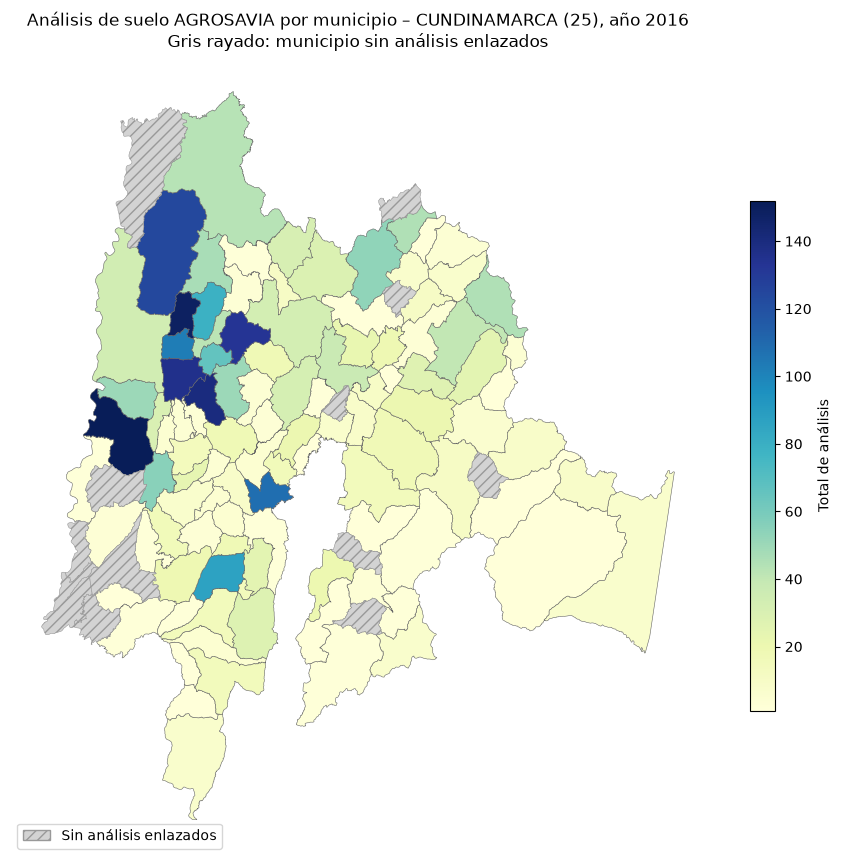

In [30]:
# Desarrollo

# Año elegido
anios_disponibles = asociados["anio"].value_counts().sort_index()
print("Análisis enlazados por año:"); display(anios_disponibles)
ANIO = int(asociados["anio"].value_counts().idxmax())
print("Año elegido:", ANIO)

base_anio = asociados.loc[asociados["anio"].eq(ANIO).fillna(False).astype(bool)]
resumen_anual = (base_anio.groupby("codigo_municipio")
                 .agg(total_analisis=("id_fila", "size"),
                      ph_validos=("ph_valido", "sum"),
                      media_ph_valido=("ph_para_media", "mean"))
                 .reset_index())
resumen_anual["total_analisis"] = resumen_anual["total_analisis"].astype("Int64")
resumen_anual["ph_validos"] = resumen_anual["ph_validos"].astype("Int64")
resumen_anual["anio"] = pd.array([ANIO] * len(resumen_anual), dtype="Int64")

# Claves
municipios_validos = municipios_validos.copy()
municipios_validos["codigo_municipio"] = municipios_validos["mpio_cdpmp"].astype(str).str.strip()
assert municipios_validos["codigo_municipio"].str.fullmatch(r"\d{5}").all()
assert municipios_validos["codigo_municipio"].is_unique
assert resumen_anual["codigo_municipio"].str.fullmatch(r"\d{5}").all()
assert resumen_anual["codigo_municipio"].is_unique

mapa_municipal = municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left",
                                          validate="one_to_one", indicator=True)
assert isinstance(mapa_municipal, gpd.GeoDataFrame)
assert len(mapa_municipal) == len(municipios_validos)
assert mapa_municipal.crs == municipios_validos.crs
mapa_municipal = mapa_municipal.rename(columns={"_merge": "estado_resumen"})
mapa_municipal["estado_resumen"] = mapa_municipal["estado_resumen"].astype(str).replace(
    {"both": "con_resumen", "left_only": "sin_resumen"})

sin_resumen = mapa_municipal.loc[mapa_municipal["estado_resumen"].eq("sin_resumen"), ["codigo_municipio"]]
chequeo_geom = resumen_anual.merge(municipios_validos[["codigo_municipio"]], on="codigo_municipio",
                                   how="left", validate="one_to_one", indicator=True)
resumen_sin_geometria = chequeo_geom.loc[chequeo_geom["_merge"].eq("left_only")].drop(columns="_merge")
print("Municipios sin resumen en el año:", len(sin_resumen))
print("Códigos del resumen sin geometría apta:"); display(resumen_sin_geometria)

conciliacion_mapa = pd.DataFrame({
    "concepto": [f"análisis enlazados {ANIO}", "en polígonos del mapa", "en códigos sin geometría", "suma"],
    "analisis": [len(base_anio), int(mapa_municipal["total_analisis"].sum()),
                 int(resumen_sin_geometria["total_analisis"].sum()),
                 int(mapa_municipal["total_analisis"].sum()) + int(resumen_sin_geometria["total_analisis"].sum())],
})
display(conciliacion_mapa)
assert conciliacion_mapa.loc[3, "analisis"] == len(base_anio)

# Área en proyección métrica (MAGNA-SIRGAS Origen Nacional, EPSG:9377)
mapa_metrico = mapa_municipal.to_crs(epsg=9377)
mapa_municipal["area_ha"] = mapa_metrico.geometry.area / 10000
display(mapa_municipal[["codigo_municipio", "total_analisis", "area_ha"]].head())
if "mpio_narea" in mapa_municipal.columns:
    dif_area = 100 * (mapa_municipal["area_ha"] / 100 - mapa_municipal["mpio_narea"]) / mapa_municipal["mpio_narea"]
    print("Diferencia % entre area_ha calculada (EPSG:9377) y mpio_narea del DANE (km²):",
          dif_area.abs().describe()[["mean", "max"]].round(6).to_dict())

# Diferencia de catálogos: códigos DIVIPOLA 2024 frente a MGN 2025
codigos_divipola = set(territorio["codigo_municipio"].dropna())
codigos_mgn = set(municipios_validos["codigo_municipio"])
print("Códigos solo en DIVIPOLA 2024:", sorted(codigos_divipola - codigos_mgn))
print("Códigos solo en MGN 2025:", sorted(codigos_mgn - codigos_divipola))

# Mapa de un departamento (por defecto: el de más análisis en el año)
DEPTO = (mapa_municipal.dropna(subset=["total_analisis"])
         .groupby(mapa_municipal["codigo_municipio"].str[:2])["total_analisis"].sum().idxmax())
print("Departamento del mapa:", DEPTO)
mapa_depto = mapa_municipal.loc[mapa_municipal["codigo_municipio"].str[:2].eq(DEPTO)].copy()
mapa_depto["total_plot"] = mapa_depto["total_analisis"].astype("float64")  # NA → NaN solo para graficar

fig, ax = plt.subplots(figsize=(9, 9))
mapa_depto.plot(column="total_plot", ax=ax, cmap="YlGnBu", edgecolor="0.4", linewidth=0.4, legend=True,
                legend_kwds={"label": "Total de análisis", "shrink": 0.6},
                missing_kwds={"color": "lightgrey", "hatch": "///", "edgecolor": "0.6",
                              "label": "Sin análisis enlazados"})
nombre_depto = territorio_por_codigo.loc[territorio_por_codigo["codigo_departamento"].eq(DEPTO),
                                         "nombre_departamento_divipola"].iloc[0] if (territorio_por_codigo["codigo_departamento"] == DEPTO).any() else DEPTO
ax.set_title(f"Análisis de suelo AGROSAVIA por municipio – {nombre_depto} ({DEPTO}), año {ANIO}\n"
             "Gris rayado: municipio sin análisis enlazados")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="lightgrey", hatch="///", edgecolor="0.6", label="Sin análisis enlazados")],
          loc="lower left")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT + "/mapa_analisis.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

El `merge` por `codigo_municipio` es una unión de atributos: asocia el resumen anual a los polígonos solo porque el código coincide, sin mirar la forma ni la posición de las geometrías. Con el año **2016** (14.539 análisis enlazados, el año con más registros), `validate="one_to_one"` se cumplió y se conservaron los **1.122 polígonos**. Hay **710 con resumen y 412 sin análisis enlazados** ese año. Ningún código del resumen quedó sin geometría, y la conciliación cuadra: 14.539 análisis del año = 14.539 en polígonos + 0 en códigos sin geometría.

**DIVIPOLA 2024 frente a MGN 2025.** Los 1.122 códigos coinciden exactamente entre los dos catálogos, sin códigos exclusivos de ninguno. En esta copia, el cambio de corte no hace perder enlaces. Aun así, los nombres pueden diferir (el MGN usa la denominación vigente) y los límites pueden haberse ajustado entre versiones, como indica `mpio_nano`.

**Área.** Las hectáreas se calcularon tras transformar a EPSG:9377 (MAGNA-SIRGAS Origen Nacional, en metros), y coinciden con `mpio_narea` del DANE con diferencia prácticamente nula. Calcularlas sobre EPSG:4326 daría "grados cuadrados", una unidad sin sentido físico: un grado de longitud mide distinto según la latitud, así que ese valor no puede convertirse a hectáreas con un factor fijo.

**Mapa.** Se eligió Cundinamarca (25). 103 de sus 116 municipios tienen análisis; los 13 restantes aparecen en gris rayado. Ese gris significa "sin análisis enlazados en 2016", no cero análisis: pueden existir análisis de otros años, no enlazados o de otros laboratorios. La media de pH describe solo las muestras disponibles, no el suelo del municipio.

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

Atributos IGAC conservados: ['UCCapacida']
Tipos resultantes del overlay: {'Polygon': 5, 'MultiPolygon': 4}
Contactos de área cero (líneas, puntos o polígonos degenerados): 0 {}
Piezas poligonales de área positiva: 15 | área total: 4545.23 ha
IGAC: suma de áreas 4545.23 ha vs área de la unión 4545.23 ha → solapamiento -0.00 ha


,id_igac,area_original_ha,area_intersectada_ha,diferencia_ha,porcentaje_dentro,estado,area_atributo_igac,dif_atributo_pct
0,0,1597.896924,1597.896924,9.322321e-12,100.0,completo_dentro_de_municipios,1599.710606,-0.113
1,1,359.443210,359.443210,1.136868e-13,100.0,completo_dentro_de_municipios,359.860856,-0.116
2,2,1288.865623,1288.865623,5.229595e-12,100.0,completo_dentro_de_municipios,1290.315155,-0.112
3,3,876.420920,876.420920,5.684342e-13,100.0,completo_dentro_de_municipios,877.464418,-0.119
4,4,422.606857,422.606857,0.000000e+00,100.0,completo_dentro_de_municipios,423.111236,-0.119


Piezas < 5 ha (posibles astillas de borde): 7 | área total: 3.892 ha


,codigo_municipio,id_igac,igac_uccapacida,area_original_ha,area_ha,es_astilla
8,25740,0,2c,1597.896924,1253.714345,False
10,25754,0,2c,1597.896924,341.960743,False
12,25754,0,2c,1597.896924,2.150436,True
11,25754,0,2c,1597.896924,0.056094,True
9,25740,0,2c,1597.896924,0.015305,True
13,25754,1,2c,359.443210,359.443210,False
14,25754,2,2c,1288.865623,1094.927501,False
2,25099,2,2c,1288.865623,104.680216,False
3,25473,2,2c,1288.865623,89.217455,False
4,25473,2,2c,1288.865623,0.040450,True


,codigo_municipio,area_ha,area_intersectada_ha,poligonos_igac
148,11001,162054.083433,1297.398414,2.0
465,25099,10220.924552,104.680216,1.0
515,25473,10581.849543,90.887269,2.0
541,25740,12199.538808,1253.729650,1.0
544,25754,18723.112080,1798.537985,3.0


Municipios donde la suma intersectada supera el área municipal (efecto del solapamiento): 0


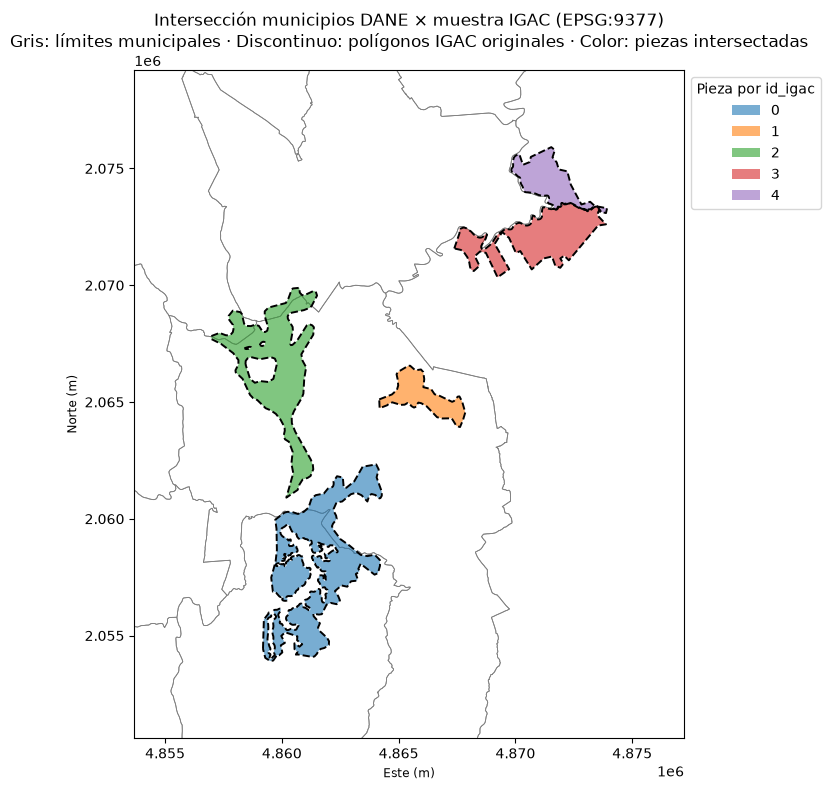

In [31]:
# Desarrollo

ATRIBUTOS_IGAC = [c for c in capacidad_valida.columns
                  if c not in ("geometry", "fila_original") and pd.Series([c]).str.contains(r"(?i)clase|capac|uso|simb|ucs").iloc[0]]
if not ATRIBUTOS_IGAC:
    ATRIBUTOS_IGAC = [c for c in capacidad_valida.columns if c not in ("geometry", "fila_original")][:1]
print("Atributos IGAC conservados:", ATRIBUTOS_IGAC)

municipios_m = municipios_validos[["codigo_municipio", "geometry"]].to_crs(epsg=9377)
capacidad_m = capacidad_valida[["fila_original"] + ATRIBUTOS_IGAC + ["geometry"]].rename(
    columns={"fila_original": "id_igac", **{c: "igac_" + c.lower() for c in ATRIBUTOS_IGAC}}).to_crs(epsg=9377)
capacidad_m["area_original_ha"] = capacidad_m.geometry.area / 10000
assert not set(municipios_m.columns).intersection(capacidad_m.columns) - {"geometry"}

piezas_brutas = gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)
print("Tipos resultantes del overlay:", piezas_brutas.geom_type.value_counts().to_dict())

# Separar componentes de colecciones y clasificar
piezas = piezas_brutas.explode(index_parts=False).reset_index(drop=True)
piezas["area_ha"] = piezas.geometry.area / 10000
es_poligonal = piezas.geom_type.isin(["Polygon", "MultiPolygon"])
contactos = piezas.loc[~es_poligonal | piezas["area_ha"].le(0)].copy()
print("Contactos de área cero (líneas, puntos o polígonos degenerados):", len(contactos),
      contactos.geom_type.value_counts().to_dict())
intersecciones = piezas.loc[es_poligonal & piezas["area_ha"].gt(0)].copy().reset_index(drop=True)
print("Piezas poligonales de área positiva:", len(intersecciones), "| área total:", round(intersecciones["area_ha"].sum(), 2), "ha")

# Riesgo de solapamiento entre polígonos IGAC
union_igac = capacidad_m.geometry.union_all() if hasattr(capacidad_m.geometry, "union_all") else capacidad_m.geometry.unary_union
area_suma_igac = capacidad_m["area_original_ha"].sum()
area_union_igac = union_igac.area / 10000
print(f"IGAC: suma de áreas {area_suma_igac:.2f} ha vs área de la unión {area_union_igac:.2f} ha "
      f"→ solapamiento {area_suma_igac - area_union_igac:.2f} ha")

# Contraste por polígono IGAC
TOLERANCIA_HA = 0.01
contraste_igac = (capacidad_m[["id_igac", "area_original_ha"]]
                  .merge(intersecciones.groupby("id_igac")["area_ha"].sum().rename("area_intersectada_ha").reset_index(),
                         on="id_igac", how="left", validate="one_to_one"))
contraste_igac["diferencia_ha"] = contraste_igac["area_original_ha"] - contraste_igac["area_intersectada_ha"]
contraste_igac["porcentaje_dentro"] = (100 * contraste_igac["area_intersectada_ha"] / contraste_igac["area_original_ha"]).round(2)
contraste_igac["estado"] = np.select(
    [contraste_igac["area_intersectada_ha"].isna(),
     contraste_igac["diferencia_ha"].abs().le(TOLERANCIA_HA),
     contraste_igac["diferencia_ha"].gt(TOLERANCIA_HA)],
    ["sin_interseccion", "completo_dentro_de_municipios", "parcialmente_fuera_de_municipios"],
    default="intersectada_mayor_que_original_revisar")
if "Area" in capacidad_valida.columns:
    area_attr = capacidad_valida.set_index("fila_original")["Area"]
    contraste_igac["area_atributo_igac"] = contraste_igac["id_igac"].map(area_attr)
    contraste_igac["dif_atributo_pct"] = (100 * (contraste_igac["area_original_ha"] - contraste_igac["area_atributo_igac"])
                                          / contraste_igac["area_atributo_igac"]).round(3)
display(contraste_igac)

# Astillas: piezas muy pequeñas por desajuste de bordes entre IGAC y MGN
UMBRAL_ASTILLA_HA = 5
intersecciones["es_astilla"] = intersecciones["area_ha"] < UMBRAL_ASTILLA_HA
print(f"Piezas < {UMBRAL_ASTILLA_HA} ha (posibles astillas de borde):", int(intersecciones["es_astilla"].sum()),
      "| área total:", round(intersecciones.loc[intersecciones["es_astilla"], "area_ha"].sum(), 3), "ha")
display(intersecciones.drop(columns="geometry").sort_values(["id_igac", "area_ha"], ascending=[True, False]))

# Área intersectada por municipio, integrada al mapa
area_mpio = intersecciones.groupby("codigo_municipio").agg(
    area_intersectada_ha=("area_ha", "sum"), poligonos_igac=("id_igac", "nunique")).reset_index()
mapa_municipal = mapa_municipal.drop(columns=["area_intersectada_ha", "poligonos_igac"], errors="ignore")
mapa_municipal = mapa_municipal.merge(area_mpio, on="codigo_municipio", how="left", validate="one_to_one")
assert len(mapa_municipal) == len(municipios_validos)
display(mapa_municipal.loc[mapa_municipal["area_intersectada_ha"].notna(),
                           ["codigo_municipio", "area_ha", "area_intersectada_ha", "poligonos_igac"]])
excede = mapa_municipal["area_intersectada_ha"] > mapa_municipal["area_ha"] + TOLERANCIA_HA
print("Municipios donde la suma intersectada supera el área municipal (efecto del solapamiento):", int(excede.sum()))

# Mapa de la extensión de la muestra
minx, miny, maxx, maxy = capacidad_m.total_bounds
margen = 0.15 * max(maxx - minx, maxy - miny)
fig, ax = plt.subplots(figsize=(10, 8))
municipios_m.cx[minx - margen:maxx + margen, miny - margen:maxy + margen].plot(
    ax=ax, facecolor="none", edgecolor="0.5", linewidth=0.6)
intersecciones.plot(ax=ax, column="id_igac", categorical=True, cmap="tab10", alpha=0.6, legend=True,
                    legend_kwds={"title": "Pieza por id_igac", "loc": "upper left", "bbox_to_anchor": (1, 1)})
capacidad_m.boundary.plot(ax=ax, color="black", linewidth=1.4, linestyle="--")
ax.set_xlim(minx - margen, maxx + margen); ax.set_ylim(miny - margen, maxy + margen)
ax.set_title("Intersección municipios DANE × muestra IGAC (EPSG:9377)\n"
             "Gris: límites municipales · Discontinuo: polígonos IGAC originales · Color: piezas intersectadas")
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
plt.tight_layout()
plt.savefig(OUT + "/mapa_interseccion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

`Overlay` es una **operación espacial**: corta cada polígono IGAC con los límites municipales según la posición y forma de las geometrías, sin código compartido.

**Resultado.**

- **Piezas:** el overlay devolvió 9 geometrías (5 `Polygon` y 4 `MultiPolygon`), sin contactos de área cero. Al separarlas quedan **15 piezas poligonales**, que suman **4.545,23 ha**.
- **Municipios tocados:** cinco, todos en la Sabana de Bogotá: Soacha (1.798,5 ha, 3 polígonos), Bogotá D.C. (1.297,4 ha), Sibaté (1.253,7 ha), Bojacá (104,7 ha) y Mosquera (90,9 ha).
- **Contraste por polígono:** cada polígono IGAC queda **100 % dentro de municipios**. La diferencia entre su área original y la suma de sus piezas es inferior a 1e−10 ha, muy por debajo de la tolerancia de 0,01 ha.
- **Atributo `Area` del IGAC:** difiere alrededor de 0,1 % del área recalculada en EPSG:9377 (p. ej. 1.599,71 frente a 1.597,90 ha). La diferencia se explica porque el IGAC lo calculó en otra proyección. Por eso se usó la geometría de cada pieza, como pide el enunciado.
- **Astillas de borde:** hay **7 piezas menores de 5 ha** (de 0,007 a 2,15 ha). Son astillas causadas porque los límites del IGAC y del MGN no coinciden exactamente. Se conservan y se marcan con `es_astilla`. No se eliminan, porque juntas suman menos de 4 ha.

- **Solapamiento.** La suma de las áreas IGAC (4.545,23 ha) es igual al área de su unión, de modo que los cinco polígonos no se solapan entre sí. Por eso `area_intersectada_ha` en cada municipio sí puede leerse como área única cubierta por la muestra. Si hubiera solapamientos, la suma contaría dos veces la zona común.

- **Alcance.** Los cinco polígonos son todos de la clase `2c` y cubren menos del 1 % del área de los municipios que tocan (en Bogotá D.C., 1.297 de 162.054 ha). No permiten estimar la capacidad de uso de ningún municipio completo. Tampoco asignan una clase IGAC a las muestras AGROSAVIA, que no tienen ubicación propia, solo un municipio asociado.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [32]:
# Desarrollo

# Tabla de análisis integrados (sin geometría)
columnas_originales = suelo_original.columns.tolist()
columnas_salida = (["id_fila"] + columnas_originales +
                   ["fecha_dt", "fecha_estado", "anio", "ph", "ph_estado", "ph_valido",
                    "clave_dpto", "clave_mpio", "codigo_departamento", "codigo_municipio",
                    "nombre_departamento_divipola", "nombre_municipio_divipola",
                    "longitud_territorial", "latitud_territorial",
                    "estado_union_inicial", "estado_union", "procedencia_enlace"])
analisis_integrados = union[columnas_salida].copy()
analisis_integrados["fuente_suelo"] = "agrosavia.csv"
analisis_integrados["catalogo_territorial"] = "DIVIPOLA 2024"

# Tipos del contrato
for c in columnas_originales + ["fecha_estado", "ph_estado", "clave_dpto", "clave_mpio", "codigo_departamento",
                                "codigo_municipio", "nombre_departamento_divipola", "nombre_municipio_divipola",
                                "estado_union_inicial", "estado_union", "procedencia_enlace",
                                "fuente_suelo", "catalogo_territorial"]:
    analisis_integrados[c] = analisis_integrados[c].astype("string")
analisis_integrados["id_fila"] = analisis_integrados["id_fila"].astype("Int64")
analisis_integrados["anio"] = analisis_integrados["anio"].astype("Int64")
analisis_integrados["ph"] = analisis_integrados["ph"].astype("float64")
analisis_integrados["ph_valido"] = analisis_integrados["ph_valido"].astype(bool)
analisis_integrados["longitud_territorial"] = analisis_integrados["longitud_territorial"].astype("float64")
analisis_integrados["latitud_territorial"] = analisis_integrados["latitud_territorial"].astype("float64")
assert len(analisis_integrados) == len(suelo_original)
assert analisis_integrados.loc[analisis_integrados["procedencia_enlace"].eq("sin_enlace"), "codigo_municipio"].isna().all()

ruta_parquet = OUT + "/analisis_integrados.parquet"
analisis_integrados.to_parquet(ruta_parquet, engine="pyarrow", compression="snappy", index=False)
releido = pd.read_parquet(ruta_parquet, engine="pyarrow")
print("Filas escritas/releídas:", len(analisis_integrados), len(releido))
print("Tipos releídos:"); display(releido.dtypes.astype(str).to_frame("dtype").T)
pd.testing.assert_frame_equal(
    analisis_integrados.sort_values("id_fila").reset_index(drop=True),
    releido.sort_values("id_fila").reset_index(drop=True),
    check_dtype=True)
print("Parquet: contenido y tipos idénticos tras la relectura.")

# CSV de control
controles = pd.concat([
    conteos_entrada.assign(control="entrada").rename(columns={"tabla": "detalle", "filas": "valor"})[["control", "detalle", "valor"]],
    control_conversion.rename(columns={"control": "detalle", "conteo": "valor"}).assign(control="conversion")[["control", "detalle", "valor"]],
    cobertura_antes.rename(columns={"estado": "detalle", "analisis": "valor"}).assign(control="cobertura_antes")[["control", "detalle", "valor"]],
    cobertura_despues.rename(columns={"estado": "detalle", "analisis": "valor"}).assign(control="cobertura_despues")[["control", "detalle", "valor"]],
    conciliacion.rename(columns={"concepto": "detalle", "analisis": "valor"}).assign(control="conciliacion_resumen")[["control", "detalle", "valor"]],
    conciliacion_mapa.rename(columns={"concepto": "detalle", "analisis": "valor"}).assign(control="conciliacion_mapa")[["control", "detalle", "valor"]],
], ignore_index=True)
controles.to_csv(OUT + "/controles.csv", index=False, encoding="utf-8-sig")
control_geometrias.to_csv(OUT + "/control_crs_geometrias.csv", index=False, encoding="utf-8-sig")
geometrias_apartadas.to_csv(OUT + "/geometrias_apartadas.csv", index=False, encoding="utf-8-sig")
equivalencias.to_csv(OUT + "/equivalencias.csv", index=False, encoding="utf-8-sig")
resumen_municipal.to_csv(OUT + "/resumen_municipal.csv", index=False, encoding="utf-8-sig")
resumen_anual.to_csv(OUT + "/resumen_anual.csv", index=False, encoding="utf-8-sig")
contraste_igac.to_csv(OUT + "/contraste_igac.csv", index=False, encoding="utf-8-sig")
analisis_integrados.loc[analisis_integrados["procedencia_enlace"].eq("sin_enlace")].to_csv(
    OUT + "/registros_pendientes.csv", index=False, encoding="utf-8-sig")

# GeoPackage: archivo nuevo en cada ejecución, dos capas
ruta_gpkg = OUT + "/resultados_espaciales.gpkg"
if os.path.exists(ruta_gpkg):
    os.remove(ruta_gpkg)
mapa_municipal_export = mapa_municipal.copy()
mapa_municipal_export["estado_resumen"] = mapa_municipal_export["estado_resumen"].astype(str)
intersecciones_export = intersecciones.copy()
for capa in (mapa_municipal_export, intersecciones_export):
    for c in capa.columns:
        if isinstance(capa[c].dtype, pd.CategoricalDtype):
            capa[c] = capa[c].astype(str)

mapa_municipal_export.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones_export.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)

capa_mpios = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")
capa_inter = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="intersecciones", engine="pyogrio")
for nombre, original, releida, clave in [("municipios", mapa_municipal_export, capa_mpios, "codigo_municipio"),
                                         ("intersecciones", intersecciones_export, capa_inter, "id_igac")]:
    print(f"== {nombre} ==")
    print("Filas:", len(original), "→", len(releida), "| CRS igual:", releida.crs == original.crs,
          "| geometría activa:", releida.geometry.name)
    assert len(releida) == len(original)
    assert releida.crs == original.crs
    assert releida[clave].astype(str).tolist() == original[clave].astype(str).tolist()
    area_o = original.to_crs(epsg=9377).geometry.area.to_numpy()   # áreas comparadas en proyección métrica
    area_r = releida.to_crs(epsg=9377).geometry.area.to_numpy()
    assert np.allclose(area_o, area_r, rtol=1e-9, atol=1e-6)
    difs = pd.DataFrame({"original": original.dtypes.astype(str), "releido": releida.dtypes.reindex(original.columns).astype(str)})
    print("Diferencias de tipo tras GeoPackage:"); display(difs.loc[difs["original"] != difs["releido"]])
for col in ["total_analisis", "ph_validos", "media_ph_valido", "area_ha", "area_intersectada_ha"]:
    a = pd.to_numeric(mapa_municipal_export[col], errors="coerce").astype("float64").to_numpy()
    b = pd.to_numeric(capa_mpios[col], errors="coerce").astype("float64").to_numpy()
    assert np.allclose(a, b, equal_nan=True), col
assert np.allclose(intersecciones_export["area_ha"].to_numpy(), capa_inter["area_ha"].to_numpy())
print("GeoPackage: filas, claves, CRS, geometrías, valores y áreas verificados.")
print("\nArchivos en OUT:", sorted(os.listdir(OUT)))

Filas escritas/releídas: 92738 92738
Tipos releídos:


,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,longitud_territorial,latitud_territorial,estado_union_inicial,estado_union,procedencia_enlace,fuente_suelo,catalogo_territorial
dtype,Int64,string,string,string,string,string,string,string,string,string,...,string,string,string,float64,float64,string,string,string,string,string


Parquet: contenido y tipos idénticos tras la relectura.
== municipios ==
Filas: 1122 → 1122 | CRS igual: True | geometría activa: geometry
Diferencias de tipo tras GeoPackage:


,original,releido
total_analisis,Int64,float64
ph_validos,Int64,float64
anio,Int64,float64


== intersecciones ==
Filas: 15 → 15 | CRS igual: True | geometría activa: geometry
Diferencias de tipo tras GeoPackage:


,original,releido


GeoPackage: filas, claves, CRS, geometrías, valores y áreas verificados.

Archivos en OUT: ['analisis_integrados.parquet', 'claves_ambiguas.csv', 'contraste_igac.csv', 'control_crs_geometrias.csv', 'controles.csv', 'equivalencias.csv', 'geometrias_apartadas.csv', 'mapa_analisis.png', 'mapa_interseccion.png', 'registros_pendientes.csv', 'resultados_espaciales.gpkg', 'resumen_anual.csv', 'resumen_municipal.csv']


**Interpretación:**

**Parquet.** `analisis_integrados.parquet` guarda las **92.738 filas** con las 32 columnas originales como texto, las columnas tipadas del contrato, estado y procedencia del enlace y las coordenadas territoriales con nombres inequívocos. Tras releerlo y ordenarlo por `id_fila`, `pd.testing.assert_frame_equal` confirmó que contenido, tipos y número de filas son idénticos. Los códigos siguen siendo texto y los 43 análisis sin enlace mantienen sus códigos ausentes.

**GeoPackage.** El archivo se borra y se crea de nuevo en cada ejecución. Se escriben sus dos capas:

- `municipios`: 1.122 polígonos, en EPSG:4326.
- `intersecciones`: 15 piezas, en EPSG:9377.

Al releerlas coinciden filas, claves, CRS, geometría activa, valores y áreas, con tolerancia. La única diferencia de tipos es que `total_analisis`, `ph_validos` y `anio` vuelven como `float64` en lugar de `Int64`. El formato GPKG no tiene un entero que admita ausentes, así que los municipios sin resumen fuerzan el decimal. Por eso esos campos se compararon numéricamente.

**Reproducibilidad.** Todas las escrituras reemplazan archivos concretos de `OUT` y los CSV de entrada no se modifican. Reiniciar el kernel y reejecutar produce el mismo contenido.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
